# PPO from scratch on your own CartPole, step by step

This notebook is the earlier `ppo_step_by_step.ipynb` (based on ericyangyu/PPO-for-Beginners) with **one big change**:
the Gymnasium `Pendulum-v1` environment is gone. PPO now balances the **CartPole you wrote from scratch** in `CartPole_hillclimb.py`
(same physics, same `force_mag = 50`, same termination rules). **No RL library and no Gymnasium anywhere.** Only NumPy, PyTorch (networks) and Matplotlib (plots).

The PPO training itself is the same as before: same rollout, same rewards-to-go, same advantage normalisation, same clipped objective,
same 10 gradient steps per batch, same Adam and same hyperparameters (`2048` steps per batch, `gamma=0.99`, `lr=3e-4`, `clip=0.2`).
Only the numbers that depend on the environment changed, and each one is explained where it appears.

## What changed compared with the Pendulum notebook

| | Pendulum notebook | This notebook |
|---|---|---|
| Environment | `gym.make('Pendulum-v1')` | `CartPole` class from your file (physics unchanged) |
| Observation | 3 numbers (cos, sin, angular velocity) | 4 numbers: `x, x_dot, theta, theta_dot` |
| Action | torque in [-2, 2] | force in [-50, 50] newtons |
| Reward | negative cost every step | **+1 for every step the pole stays up** |
| Episode ends | never terminates, cut at 200 steps | **terminates** when `abs(x) > 2.4` or `abs(theta) > 12 degrees`, cut at 500 steps |
| Good score | about -150 | **500** (pole survives the whole episode) |

## How the notebook is organised

**Part A: theory (read once, then come back whenever the code feels like magic)**
1. Why PPO exists
2. What kind of environment this is
3. Terminology
4. Building the PPO formula one step at a time
5. A numerical example you can check by hand
6. Project design

**Part B: implementation (run the cells in order)**
Stages 0 to 13, each with a "line to equation" table, then debugging, comparison with earlier algorithms, "when would I use this", and experiments.

One PPO iteration is always:

1. **Rollout**: play with the current actor and record everything
2. **Rewards-to-go**: for each step, the discounted sum of future rewards
3. **Advantage**: was the action better or worse than the critic expected?
4. **Update**: several gradient steps with the *clipped* objective
5. Repeat

# Part A: Theory

## 1. Why PPO exists

PPO is the end of a chain of fixes. Each algorithm in the chain was invented because the previous one had a specific problem.

| Algorithm | What it does | The problem that led to the next one |
|---|---|---|
| **Hill climbing** (your `CartPole_hillclimb.py`) | Nudge the policy parameters randomly, keep the change if the episode reward went up | Needs many full episodes just to compare two parameter sets. Noisy. Cannot use per-step information. Does not scale to a neural network with thousands of parameters. |
| **REINFORCE** | Policy gradient: increase the probability of actions in proportion to the return that followed | **High variance**: one lucky or unlucky episode swings the gradient a lot. Also throws the data away after one gradient step. |
| **Actor-critic / A2C** | Add a critic `V(s)` and use the **advantage** `R - V(s)` instead of the raw return | Variance is much lower, but each batch is still used for **one** step. And one step that is too large can wreck the policy (see below). |
| **TRPO** | Allow several steps, but constrain how far the new policy may move from the old one (KL constraint) | Correct but complicated: second-order optimisation, conjugate gradient, line search. Hard to implement and slow. |
| **PPO** | Get almost the same effect as TRPO with a **simple clipped loss** and plain Adam | This notebook |

**The core problem PPO solves.** In supervised learning a bad gradient step costs you one bad batch; the next batch will correct it.
In RL the *data comes from the policy itself*. If one update makes the policy much worse, the next batch is collected by that worse policy,
so you get worse data, which gives a worse update... and the policy can collapse and never recover.
So we want to **reuse each expensive batch for several gradient steps (sample efficiency)** but **never let the policy move too far from the one that collected the data (stability)**.
PPO's clipping is a cheap way to enforce exactly that.

**When NOT to use PPO**
- Simulation is extremely expensive and every sample matters: off-policy methods (SAC, TD3) reuse old data much more, so they are usually more sample efficient.
- The problem is tiny (small discrete state space): tabular Q-learning is simpler and exact.
- You need a deterministic, very precise controller from very few samples: classical control (LQR/PID) or model-based methods win.
- You cannot afford to tune: PPO is *robust* but still sensitive to batch size, learning rate and reward scale.

## 2. What kind of environment is this?

| Property | CartPole (your version) | Consequence |
|---|---|---|
| State space | **Continuous**, 4 numbers: cart position `x`, cart velocity `x_dot`, pole angle `theta`, pole angular velocity `theta_dot` | We need a function approximator (neural network); no table is possible |
| Action space | **Continuous**, one number: horizontal force in [-50, 50] N | The policy outputs a **probability distribution** over real numbers (a Gaussian), not a softmax over choices |
| Dynamics | Deterministic (the physics has no randomness) | All randomness comes from our own policy's exploration noise and the random start |
| Episodes | **Episodic with termination**: ends when the cart leaves the track or the pole falls | We must carefully compute returns inside each episode and never mix episodes |
| Reward | +1 per step alive | Return = survival time. Longer episode = better. Max is 500 here |
| Observability | Fully observed (the state is the observation) | A plain feed-forward network is enough; no memory needed |

Why this matters for PPO specifically: PPO is **on-policy** (it learns only from data collected by the *current* policy) and works for both discrete and continuous actions.
For continuous actions the standard choice is a **Gaussian policy**: the actor outputs the *mean*, and a fixed or learned standard deviation controls the exploration noise.

## 3. Terminology

| Term | Meaning in this notebook |
|---|---|
| **State / observation** `s` | The 4 numbers `[x, x_dot, theta, theta_dot]` |
| **Action** `a` | The number sampled from the actor's Gaussian. We interpret it as *a fraction of the maximum force* (details in Stage 4) |
| **Reward** `r` | +1 each step the pole is still up |
| **Episode** | One run from `reset()` until the pole falls, the cart leaves the track, or 500 steps |
| **Timestep** | One call to `env.step` |
| **Return** | Sum of (discounted) rewards of the future |
| **Reward-to-go** `R_t` | Discounted sum of rewards from step `t` until the end of *that episode* |
| **Discount** `gamma` | How much a reward `k` steps in the future is worth: `gamma^k` |
| **Policy** `pi(a|s)` | The actor: the probability (density) of action `a` in state `s` |
| **Actor** | Network `state -> mean of the action` |
| **Critic / value function** `V(s)` | Network `state -> expected reward-to-go` from that state |
| **Advantage** `A_t` | `R_t - V(s_t)`: how much better than expected this step turned out |
| **Log probability** | `log pi(a|s)`. We store it during the rollout (`old`) and recompute it during the update (`new`) |
| **Ratio** `r_t` | `pi_new(a|s) / pi_old(a|s)`: how much the policy has changed for this action |
| **Clip range** `epsilon` | How far the ratio is allowed to matter: `[1-eps, 1+eps] = [0.8, 1.2]` |
| **Batch** | All steps collected in one rollout (about 2048 here) |
| **On-policy** | Data must come from the policy being trained |
| **Truncation** | An episode cut by a time limit (500), not by failure |

## 4. Building the PPO formula one step at a time

**Step 1: what we want.** Maximise the expected discounted return of the policy `pi_theta` (theta = network weights):

$$J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta}\left[\sum_t \gamma^t r_t\right]$$

**Step 2: the policy gradient.** We cannot differentiate through the physics, but there is a trick (the log-derivative trick):

$$\nabla_\theta J = \mathbb{E}\left[\sum_t \nabla_\theta \log \pi_\theta(a_t|s_t)\; R_t\right]$$

Meaning: *raise the log-probability of each action taken, weighted by how good the future was after it.*

**Step 3: use rewards-to-go.** An action can only influence rewards that come *after* it, so we use
$R_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \dots$ instead of the whole episode return. This removes useless noise.

**Step 4: subtract a baseline (the critic).** If every action in a state gets return around 80, pushing all of them up is pointless.
We only care whether an action was better *than usual for that state*:

$$A_t = R_t - V_\phi(s_t)$$

Subtracting a function of the state does not change the expected gradient but reduces variance a lot. The critic `V_phi` is trained by regression: `loss = mean((V(s_t) - R_t)^2)`.
(We also **normalise** the advantages in the batch to mean 0, std 1. Not in the theory, but it makes learning much more stable.)

**Step 5: the vanilla loss and its danger.** The loss `-mean(log pi(a_t|s_t) * A_t)` is only valid for data from the *current* policy. After one gradient step the data is "old".
Taking several steps on it would drift away from the validity of the formula, and one big step can destroy the policy.

**Step 6: importance sampling gives a safe way to reuse the batch.** The data came from `pi_old`, but we want to evaluate `pi_new`.
Reweight each sample by the ratio:

$$r_t(\theta) = \frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)} = \exp\big(\log\pi_\theta - \log\pi_{old}\big)$$

The surrogate objective is `mean(r_t * A_t)`. At the start of an iteration `theta = theta_old`, so every ratio is exactly **1**.
(We use `exp(difference of logs)` because it is numerically more stable than dividing two tiny probabilities.)

**Step 7: the problem with the ratio.** If `A_t > 0`, maximising `r_t * A_t` pushes `r_t` up *without limit*. If we take many steps, the ratio can become huge: the policy has changed a lot, and our "old data" is no longer representative.

**Step 8: the PPO clip.**

$$L^{CLIP}(\theta) = \mathbb{E}_t\Big[\min\big(r_t A_t,\ \operatorname{clip}(r_t,\,1-\epsilon,\,1+\epsilon)\, A_t\big)\Big]$$

- `clip(r, 0.8, 1.2)` forces the ratio into `[0.8, 1.2]`.
- Taking the **minimum** of the clipped and unclipped terms makes the objective *pessimistic*: it never rewards you for moving the ratio outside the band in the direction that would look "better", but it **does** still penalise you for moving the wrong way.
- The effect: once a sample's ratio leaves the band in the profitable direction, its gradient becomes **zero**. That sample stops pushing the policy further.

**Step 9: the full thing we implement.**

- Actor loss: `L_actor = -mean( min(r_t A_t, clip(r_t, 0.8, 1.2) A_t) )` (minus because Adam *minimises* but we want to *maximise*)
- Critic loss: `L_critic = mean( (V(s_t) - R_t)^2 )`
- Both are optimised with Adam, **separately** (two separate networks, two optimisers), for `n_updates_per_iteration = 10` gradient steps on the same batch.

## 5. A numerical example you can check by hand

**Rewards-to-go.** Rewards `[1, 1, 1, 1]`, `gamma = 0.9`, computed backwards (`R_t = r_t + gamma * R_{t+1}`):

| step | reward | reward-to-go |
|---|---|---|
| 3 | 1 | 1 |
| 2 | 1 | 1 + 0.9 x 1 = 1.9 |
| 1 | 1 | 1 + 0.9 x 1.9 = 2.71 |
| 0 | 1 | 1 + 0.9 x 2.71 = 3.439 |

**Advantage.** The critic says `V(s) = 40`, but the real reward-to-go was `55`. Then `A = 55 - 40 = +15`: this action led to something better than expected, so make it more likely.

**The clip.** `epsilon = 0.2`, so the band is `[0.8, 1.2]`. Take two samples with advantage `+2` and `-2` and look at different ratios:

| Advantage | ratio | `r*A` (surr1) | `clip(r)*A` (surr2) | `min` | Gradient? |
|---|---|---|---|---|---|
| +2 | 0.7 | 1.4 | 0.8 x 2 = 1.6 | **1.4** | yes (we want the ratio back up) |
| +2 | 1.0 | 2.0 | 2.0 | **2.0** | yes |
| +2 | 1.1 | 2.2 | 2.2 | **2.2** | yes (still inside the band) |
| +2 | 1.5 | 3.0 | 1.2 x 2 = 2.4 | **2.4** | **no** (clipped: already moved enough) |
| -2 | 0.7 | -1.4 | 0.8 x -2 = -1.6 | **-1.6** | **no** (clipped: already decreased enough) |
| -2 | 1.0 | -2.0 | -2.0 | **-2.0** | yes |
| -2 | 1.1 | -2.2 | -2.2 | **-2.2** | yes |
| -2 | 1.5 | -3.0 | -2.4 | **-3.0** | yes (the ratio went the wrong way, strong correction) |

The rule in one sentence: **for `A > 0` the gradient dies when `r > 1 + eps`; for `A < 0` the gradient dies when `r < 1 - eps`.** A cell in Stage 8 reproduces this table in code so you can verify it.

## 6. Project design

**Goal:** train a neural network controller that keeps the pole up for the full 500 steps, using only trial and error.

**Pieces**

| Piece | Job |
|---|---|
| `CartPole` class | Your physics. `reset()` gives a start state, `step(force)` advances 0.02 s, `is_done()` checks failure |
| Actor network | 4 -> 64 -> 64 -> 1, outputs the mean of the action |
| Critic network | 4 -> 64 -> 64 -> 1, outputs `V(s)` |
| Gaussian with fixed std | Turns the mean into a random action and gives log-probabilities |
| Rollout loop | Collects about 2048 steps per iteration, stored in lists, then tensors |
| Update loop | 10 clipped-PPO gradient steps per batch |
| Logging | Average return, episode length, losses, clipped fraction, average force |

**Data shapes (T = number of steps in the batch, about 2048)**

| Tensor | Shape |
|---|---|
| `batch_obs` | `(T, 4)` |
| `batch_acts` | `(T, 1)` |
| `batch_log_probs` | `(T,)` |
| `batch_rtgs` | `(T,)` |
| `A_k` (advantages) | `(T,)` |

**Success criteria:** the average episode length climbs from about 10-20 steps (untrained policy) to 500 (the cap).
Because the reward is +1 per step, *episode return = episode length*.

# Part B: Implementation

## Stage 0. Imports

No `gymnasium`, no `pip install`. Everything here ships with a normal Python + PyTorch setup.
If PyTorch is missing, uncomment the first line.

In [2]:
!pip install torch numpy matplotlib

import math
import time

import numpy as np
import torch
from torch import nn
from torch.distributions import MultivariateNormal
from torch.optim import Adam
import matplotlib.pyplot as plt

print("torch:", torch.__version__)
print("numpy:", np.__version__)


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 854.3 kB/s eta 0:02:25
   ---------------------------------------- 0.8/124.1 MB 1.1 MB/s eta 0:01:54
   ---------------------------------------- 1.3/124.1 MB 1.4 MB/s eta 0:01:28
    --------------------------------------- 1.6/124.1 MB 1.5 MB/s eta 0:01:24
    --------------------------------------- 2.1/124.1 MB 1.6 MB/s eta 0:01:18
    --------------------------------------- 2.4/124.1 MB 1.6 MB/s eta 0:01:15
    --------------------------------------- 2.9/124.1 MB 1.7 MB/s eta 0:01:13
    --------------------------------------- 2.9/124.1 MB 1.7 MB/s eta 0:01:13
    -----------------

Matplotlib is building the font cache; this may take a moment.


torch: 2.14.1+cpu
numpy: 2.3.4


## Stage 1. Hyperparameters

| name | meaning | value / note |
|---|---|---|
| `timesteps_per_batch` | steps of experience collected before every update | 2048 (same as before) |
| `max_timesteps_per_episode` | time limit of one episode | **500** (was 200). A perfect episode now lasts 500 steps |
| `gamma` | discount factor | 0.99 (same). Horizon about `1/(1-gamma) = 100` steps |
| `n_updates_per_iteration` | gradient steps on each batch | 10 (same) |
| `lr` | Adam learning rate (actor and critic) | 3e-4 (same) |
| `clip` | PPO clip range epsilon | 0.2 (same) |
| `action_std` | standard deviation of the exploration noise, **in units of max force** | **0.1** which means 0.1 x 50 N = **5 N**. See Stage 4 for why this is not 0.707 any more |
| `total_timesteps` | when to stop training | 200,000 (it usually reaches 500 well before this) |
| `seed` | reproducibility | set to an int; `None` gives a different run every time |

The only hyperparameters that had to change are the ones tied to the environment: the episode limit (the task is now "survive 500 steps") and the exploration noise (the force range is 25 times wider than the torque range).

In [4]:
timesteps_per_batch = 2048
max_timesteps_per_episode = 500
gamma = 0.99
n_updates_per_iteration = 10
lr = 3e-4
clip = 0.2
action_std = 0.1            # exploration noise, as a FRACTION of the max force (0.1 -> 5 N)
save_freq = 10
total_timesteps = 200_000

seed = 0                    # set to None for a different run every time
if seed is not None:
    torch.manual_seed(seed)
    np.random.seed(seed)
    print("seed set to", seed)

print("hyperparameters loaded")

seed set to 0
hyperparameters loaded


## Stage 2. The environment: your CartPole, from scratch

### The physics (what the code below computes)

The cart (mass 1.0 kg) can be pushed horizontally with force `F`. A pole (mass 0.1 kg) is hinged on top and can fall left or right.
`length = 0.5` is the distance from the hinge to the pole's centre of mass (half the pole length, as in the classic CartPole).

Every call to `step(force)` does:

1. **Clip the force** to `[-50, 50]`.
2. Compute a helper term (the horizontal acceleration the force would give the whole system, plus a centrifugal term from the pole's swing):

$$\text{temp} = \frac{F + m_p\, l\, \dot\theta^2 \sin\theta}{M}$$

3. Angular acceleration of the pole (gravity tries to tip it over, the cart's acceleration fights it):

$$\ddot\theta = \frac{g\sin\theta - \cos\theta \cdot \text{temp}}{l\left(\frac{4}{3} - \frac{m_p\cos^2\theta}{M}\right)}$$

4. Cart acceleration (corrected for the pole pushing back):

$$\ddot x = \text{temp} - \frac{m_p\, l\, \ddot\theta \cos\theta}{M}$$

5. **Euler integration** with `dt = 0.02` s (velocities first, then positions with the *new* velocities):

`x_dot += dt * x_acc`, `theta_dot += dt * theta_acc`, `x += dt * x_dot`, `theta += dt * theta_dot`

### The episode rules (taken from your file)

- `reset()`: cart at the centre, pole tilted `0.05` rad (about 2.9 degrees), no velocity.
- `is_done()`: the episode **fails** if `abs(x) > 2.4` (cart left the track) or `abs(theta) > 12 degrees = 0.209 rad` (pole fell).

### Two small additions (everything else is unchanged)

1. **`start_noise`**: your `reset()` always starts from exactly the same state. I added a tiny random offset (+/- 0.02) to the start state, so the policy learns to recover from slightly different situations and does not memorise one single trajectory. **Set `start_noise=0.0` to get exactly your original deterministic start.**
2. **Plotting removed** from the class (`draw_cartpole` with `plt.pause` is slow and needs a pop-up window). We plot snapshots with Matplotlib in Stage 12 instead.

Your class has no reward: it only returns the state. That is fine, we define the reward in the rollout: **+1 for every step**, and the episode ends when `env.is_done()` is `True`.

In [5]:
class CartPole:
    """Your from-scratch CartPole (physics identical to CartPole_hillclimb.py)."""

    def __init__(self, start_noise=0.02):
        self.gravity = 9.8
        self.mass_cart = 1.0
        self.mass_pole = 0.1
        self.total_mass = self.mass_cart + self.mass_pole
        self.length = 0.5
        self.force_mag = 50.0
        self.dt = 0.02
        self.start_noise = start_noise      # 0.0 -> exactly your original reset
        self.reset()

    def reset(self):
        n = self.start_noise
        self.x = np.random.uniform(-n, n)
        self.x_dot = np.random.uniform(-n, n)
        self.theta = 0.05 + np.random.uniform(-n, n)
        self.theta_dot = np.random.uniform(-n, n)
        return self.get_state()

    def get_state(self):
        return [self.x, self.x_dot, self.theta, self.theta_dot]

    def is_done(self):
        if abs(self.x) > 2.4:
            return True
        if abs(self.theta) > 12 * math.pi / 180:
            return True
        return False

    def step(self, force):
        force = max(-self.force_mag, min(self.force_mag, force))
        sin_theta = math.sin(self.theta)
        cos_theta = math.cos(self.theta)

        temp = (
            force + self.mass_pole * self.length * self.theta_dot ** 2 * sin_theta
        ) / self.total_mass

        theta_acc = (
            self.gravity * sin_theta - cos_theta * temp
        ) / (
            self.length * (4 / 3 - self.mass_pole * cos_theta ** 2 / self.total_mass)
        )

        x_acc = temp - (self.mass_pole * self.length * theta_acc * cos_theta / self.total_mass)

        self.x_dot += self.dt * x_acc
        self.theta_dot += self.dt * theta_acc
        self.x += self.dt * self.x_dot
        self.theta += self.dt * self.theta_dot

        return self.get_state()


env = CartPole()
obs_dim = 4      # x, x_dot, theta, theta_dot
act_dim = 1      # one number: the force

print("obs_dim =", obs_dim, "| act_dim =", act_dim)
print("force range: [-%.0f, %.0f] N" % (env.force_mag, env.force_mag))
print("failure limits: |x| > 2.4 m  or  |theta| > %.4f rad (12 degrees)" % (12 * math.pi / 180))

obs = env.reset()
print("\nFirst observation:", np.round(obs, 4))
print("  x=%.3f, x_dot=%.3f, theta=%.3f, theta_dot=%.3f" % tuple(obs))

obs_dim = 4 | act_dim = 1
force range: [-50, 50] N
failure limits: |x| > 2.4 m  or  |theta| > 0.2094 rad (12 degrees)

First observation: [-0.0031  0.0058  0.0475  0.0157]
  x=-0.003, x_dot=0.006, theta=0.048, theta_dot=0.016


### Experiment 1: what happens if we do nothing? (force = 0)

This is the baseline PPO must beat. The pole starts 0.05 rad off vertical and gravity pulls it further. Watch how fast it falls.

With zero force the pole fell after 24 steps = 0.48 seconds


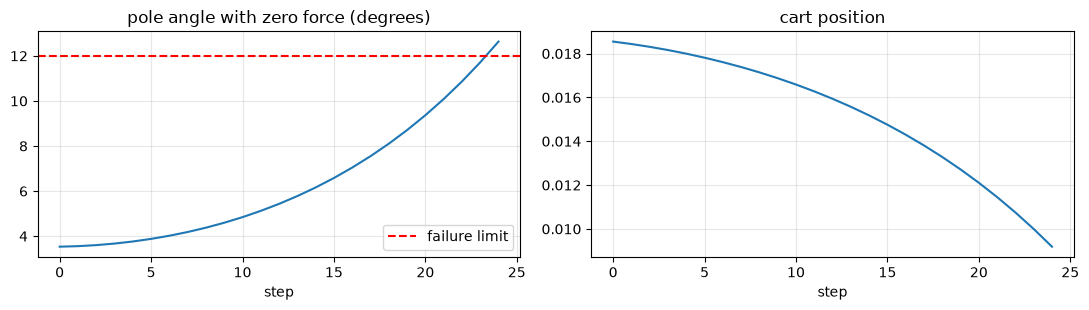

In [6]:
obs = env.reset()
zero_theta, zero_x = [obs[2]], [obs[0]]
steps_alive = 0
while not env.is_done() and steps_alive < max_timesteps_per_episode:
    obs = env.step(0.0)                  # no force at all
    zero_theta.append(obs[2]); zero_x.append(obs[0])
    steps_alive += 1

print("With zero force the pole fell after", steps_alive, "steps =", round(steps_alive * env.dt, 2), "seconds")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(np.degrees(zero_theta)); ax[0].axhline(12, color='r', ls='--', label='failure limit')
ax[0].set_title("pole angle with zero force (degrees)"); ax[0].set_xlabel("step"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(zero_x); ax[1].set_title("cart position"); ax[1].set_xlabel("step"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Experiment 2: what does a push do?

Push the cart with a constant force for **one** step and look at the accelerations. This shows the *sign convention* PPO will have to discover by itself:
pushing the cart to the right (positive force) makes the pole tilt *back* (theta decreases), which is how you catch a pole that is falling to the left, and vice versa.

In [7]:
for F in [-5.0, 0.0, +5.0]:
    env.reset()
    env.x = env.x_dot = env.theta_dot = 0.0
    env.theta = 0.05
    before = (env.x_dot, env.theta_dot)
    env.step(F)
    print(f"force {F:+5.1f} N -> x_dot change = {env.x_dot - before[0]:+.4f} m/s, "
          f"theta_dot change = {env.theta_dot - before[1]:+.4f} rad/s")

print("\nPositive force pushes the cart right (x_dot up) and makes theta_dot smaller (pole tips back).")

force  -5.0 N -> x_dot change = -0.0983 m/s, theta_dot change = +0.1619 rad/s
force  +0.0 N -> x_dot change = -0.0007 m/s, theta_dot change = +0.0158 rad/s
force  +5.0 N -> x_dot change = +0.0968 m/s, theta_dot change = -0.1304 rad/s

Positive force pushes the cart right (x_dot up) and makes theta_dot smaller (pole tips back).


## Stage 3. Actor and critic networks

Two separate small networks, both `input -> 64 -> 64 -> output` with ReLU between layers (same as the Pendulum notebook, only the input size changed from 3 to 4):

- **Actor** (the policy): state -> **mean** of the action
- **Critic**: state -> one number `V(s)`, the expected reward-to-go. For CartPole with `gamma = 0.99` this lies between 0 and about 100 (that is the sum of `0.99^k`, the maximum possible discounted survival reward).

Neither knows anything yet: the weights are random. The actor's mean is therefore a small random number, so the *initial policy is almost "push with random small force"*.

In [8]:
actor = nn.Sequential(
    nn.Linear(obs_dim, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, act_dim),
)
critic = nn.Sequential(
    nn.Linear(obs_dim, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 1),
)

actor_optim = Adam(actor.parameters(), lr=lr)
critic_optim = Adam(critic.parameters(), lr=lr)

print("ACTOR:\n", actor)
print("\nCRITIC:\n", critic)
print("\nActor parameters :", sum(p.numel() for p in actor.parameters()))
print("Critic parameters:", sum(p.numel() for p in critic.parameters()))

ACTOR:
 Sequential(
  (0): Linear(in_features=4, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)

CRITIC:
 Sequential(
  (0): Linear(in_features=4, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)

Actor parameters : 4545
Critic parameters: 4545


## Stage 4. How the actor picks an action

The actor outputs only a **mean** `mu(s)`. To explore, we build a Gaussian centred on `mu(s)` and **sample** from it:

$$a \sim \mathcal{N}\big(\mu_\theta(s),\ \sigma^2\big)$$

We also store `log pi(a|s)`, because PPO needs it later to compute the ratio.

### The action is "a fraction of the maximum force"

The network and the Gaussian work in **normalised units**; we multiply by `force_mag` only when we call the environment:

`force = a * env.force_mag`   (and `env.step` clips it to +/- 50 N)

Why not let the network output newtons directly?
- Network outputs naturally live around `-1 ... +1`. Producing `+30` requires large weights, which takes very long to learn with `lr = 3e-4`.
- With normalised actions the exploration noise has a clear meaning: `action_std = 0.1` means 10% of the maximum force = **5 N**.

### Why 0.1 and not 0.707 (the Pendulum value)?

The Pendulum notebook used variance 0.5 (std 0.707) for torques up to 2, which is about 35% of the range. Here that would be about 35 N of random shaking **every 0.02 seconds**. A 1.1 kg system gets a huge random kick each step, and the pole falls within a few steps no matter what the actor learns.
Balancing needs forces of a few newtons, so noise of about 5 N keeps exploration meaningful but survivable.

### About the log-probability and clipping

The Gaussian can sample values outside `[-1, 1]`. The environment clips the force, but we compute `log_prob` of the **unclipped** sample `a`. That is the standard practice: the policy is the Gaussian, clipping is just a property of the environment.

In [10]:
cov_var = torch.full(size=(act_dim,), fill_value=action_std ** 2)   # variance = std^2
cov_mat = torch.diag(cov_var)
print("action_std =", action_std, "-> exploration noise of about", action_std * env.force_mag, "N")
print("cov_mat:", cov_mat)

# Demo on a single observation
obs = env.reset()
obs_tensor = torch.tensor(obs, dtype=torch.float)

mean = actor(obs_tensor)
dist = MultivariateNormal(mean, cov_mat)

print("\nObservation:", np.round(obs, 4))
print("Actor's mean action: %.4f  (= %.2f N)" % (mean.item(), mean.item() * env.force_mag))

print("\nSampling 5 actions from the same distribution (they differ = exploration):")
for i in range(5):
    a = dist.sample()
    lp = dist.log_prob(a)
    print(f"  action = {a.item(): .4f} -> force = {a.item() * env.force_mag: .2f} N   log_prob = {lp.item(): .4f}")

action_std = 0.1 -> exploration noise of about 5.0 N
cov_mat: tensor([[0.0100]])

Observation: [ 0.0009 -0.0034  0.0406  0.011 ]
Actor's mean action: -0.0792  (= -3.96 N)

Sampling 5 actions from the same distribution (they differ = exploration):
  action = -0.1282 -> force = -6.41 N   log_prob =  1.2633
  action = -0.0615 -> force = -3.07 N   log_prob =  1.3681
  action = -0.0774 -> force = -3.87 N   log_prob =  1.3835
  action = -0.1293 -> force = -6.46 N   log_prob =  1.2581
  action = -0.1649 -> force = -8.24 N   log_prob =  1.0164


### Line to equation

| Code | Math |
|---|---|
| `mean = actor(obs)` | `mu_theta(s)` |
| `dist = MultivariateNormal(mean, cov_mat)` | the policy `pi_theta(. | s) = N(mu, sigma^2)` |
| `action = dist.sample()` | `a ~ pi_theta(. | s)` |
| `dist.log_prob(action)` | `log pi_theta(a | s)` |
| `force = action * env.force_mag` | convert from "fraction of max force" to newtons |

## Stage 5. Step 1 of an iteration: ROLLOUT

First watch **one episode** step by step (only the first 8 steps are printed). The untrained actor is basically random, so the episode will be short.

The three things your class does not return, we create in the loop:
- `rew = 1.0` (survived this step)
- `terminated = env.is_done()` (pole fell or cart left the track)
- the 500-step limit is the `for` loop itself (that case is a *truncation*, not a failure)

In [11]:
obs = env.reset()
ep_rews_demo = []

for ep_t in range(max_timesteps_per_episode):
    mean = actor(torch.tensor(obs, dtype=torch.float))
    dist = MultivariateNormal(mean, cov_mat)
    action = dist.sample()
    log_prob = dist.log_prob(action)

    new_obs = env.step(action.item() * env.force_mag)
    terminated = env.is_done()
    rew = 1.0
    ep_rews_demo.append(rew)

    if ep_t < 8:
        print(f"t={ep_t:3d} | obs={np.round(obs, 3)} | mean={mean.item(): .3f} | action={action.item(): .3f} "
              f"| force={action.item() * env.force_mag: .2f} N | log_prob={log_prob.item(): .3f} | reward={rew}")
    obs = new_obs
    if terminated:
        break

print("...")
print(f"Episode finished after {ep_t + 1} steps, total reward = {sum(ep_rews_demo):.0f}")
print(f"terminated (failed) = {terminated}, truncated (time limit) = {(not terminated) and ep_t + 1 == max_timesteps_per_episode}")

t=  0 | obs=[-0.002  0.003  0.031  0.005] | mean=-0.079 | action=-0.162 | force=-8.10 N | log_prob= 1.039 | reward=1.0
t=  1 | obs=[-0.005 -0.156  0.036  0.251] | mean=-0.084 | action= 0.002 | force= 0.08 N | log_prob= 1.018 | reward=1.0
t=  2 | obs=[-0.008 -0.155  0.041  0.26 ] | mean=-0.084 | action=-0.172 | force=-8.60 N | log_prob= 0.992 | reward=1.0
t=  3 | obs=[-0.014 -0.323  0.051  0.525] | mean=-0.090 | action=-0.002 | force=-0.11 N | log_prob= 0.994 | reward=1.0
t=  4 | obs=[-0.021 -0.326  0.062  0.544] | mean=-0.089 | action=-0.162 | force=-8.11 N | log_prob= 1.116 | reward=1.0
t=  5 | obs=[-0.031 -0.485  0.078  0.801] | mean=-0.078 | action=-0.114 | force=-5.71 N | log_prob= 1.318 | reward=1.0
t=  6 | obs=[-0.043 -0.597  0.098  0.992] | mean=-0.069 | action=-0.195 | force=-9.77 N | log_prob= 0.589 | reward=1.0
t=  7 | obs=[-0.058 -0.789  0.124  1.307] | mean=-0.054 | action=-0.050 | force=-2.52 N | log_prob= 1.383 | reward=1.0
...
Episode finished after 10 steps, total rewar

Now collect a **whole batch**: keep playing episodes until we have at least `timesteps_per_batch` steps. Everything is stored in plain lists, then converted to tensors.

Why `detach()` on the log-prob and action? These numbers are **fixed records of what the old policy did**. They are constants in the loss, so no gradient must flow into them.

In [13]:
batch_obs = []         # states
batch_acts = []        # actions we sampled (in "fraction of max force" units)
batch_log_probs = []   # log prob of each action under the policy that took it (the OLD policy)
batch_rews = []        # rewards, one list per episode
batch_lens = []        # length of each episode

t = 0
while t < timesteps_per_batch:
    ep_rews = []
    obs = env.reset()

    for ep_t in range(max_timesteps_per_episode):
        t += 1
        batch_obs.append(obs)

        mean = actor(torch.tensor(obs, dtype=torch.float))
        dist = MultivariateNormal(mean, cov_mat)
        action = dist.sample()
        log_prob = dist.log_prob(action)
        action = action.detach().numpy()
        log_prob = log_prob.detach()

        obs = env.step(float(action[0]) * env.force_mag)
        done = env.is_done()

        ep_rews.append(1.0)
        batch_acts.append(action)
        batch_log_probs.append(log_prob)

        if done:
            break

    batch_lens.append(ep_t + 1)
    batch_rews.append(ep_rews)

print("Episodes collected  :", len(batch_lens))
print("First 15 lengths    :", batch_lens[:15])
print("Total timesteps     :", sum(batch_lens))
print("Average length      : %.1f  (untrained: pole falls quickly)" % np.mean(batch_lens))

# lists -> tensors
batch_obs = torch.tensor(np.array(batch_obs), dtype=torch.float)
batch_acts = torch.tensor(np.array(batch_acts), dtype=torch.float)
batch_log_probs = torch.tensor(np.array(batch_log_probs), dtype=torch.float)

print("\nbatch_obs.shape       :", tuple(batch_obs.shape), " (timesteps, obs_dim)")
print("batch_acts.shape      :", tuple(batch_acts.shape), " (timesteps, act_dim)")
print("batch_log_probs.shape :", tuple(batch_log_probs.shape), " (timesteps,)")

Episodes collected  : 187
First 15 lengths    : [10, 8, 15, 12, 10, 11, 8, 12, 9, 14, 10, 10, 9, 9, 9]
Total timesteps     : 2057
Average length      : 11.0  (untrained: pole falls quickly)

batch_obs.shape       : (2057, 4)  (timesteps, obs_dim)
batch_acts.shape      : (2057, 1)  (timesteps, act_dim)
batch_log_probs.shape : (2057,)  (timesteps,)


## Stage 6. Step 2: REWARDS-TO-GO

For each timestep, the **discounted sum of all future rewards inside its own episode**:

$$R_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \dots$$

We compute it **backwards**: `rtg = reward + gamma * rtg_of_next_step`. The last step of an episode has no next step, so we start from 0 at the end of every episode. That is what keeps episodes from leaking into each other.

For CartPole with `+1` rewards, the reward-to-go is just a *discounted count of how many more steps the pole stayed up*. A step far from failure has a high `R_t` (up to about 99 for `gamma = 0.99`), a step right before failure has `R_t` close to 1.

Hand-checkable example first (the same table as in Part A):

In [14]:
example_rews = [1, 1, 1, 1]
example_gamma = 0.9
example_rtgs = []
discounted = 0
for r in reversed(example_rews):
    discounted = r + discounted * example_gamma
    example_rtgs.insert(0, discounted)
    print(f"reward={r}  ->  rtg={discounted:.3f}")
print("rewards-to-go:", [round(x, 3) for x in example_rtgs])
print("check: step 0 = 1 + 0.9 + 0.81 + 0.729 =", 1 + 0.9 + 0.81 + 0.729)

reward=1  ->  rtg=1.000
reward=1  ->  rtg=1.900
reward=1  ->  rtg=2.710
reward=1  ->  rtg=3.439
rewards-to-go: [3.439, 2.71, 1.9, 1.0]
check: step 0 = 1 + 0.9 + 0.81 + 0.729 = 3.439


In [15]:
# The real thing, on our batch
batch_rtgs = []
for ep_rews in reversed(batch_rews):
    discounted_reward = 0                      # reset at the start of every episode
    for rew in reversed(ep_rews):
        discounted_reward = rew + discounted_reward * gamma
        batch_rtgs.insert(0, discounted_reward)
batch_rtgs = torch.tensor(batch_rtgs, dtype=torch.float)

print("batch_rtgs.shape:", tuple(batch_rtgs.shape), "(one entry per timestep)")
print("first 5 rewards-to-go:", batch_rtgs[:5].numpy().round(2))
print("min / mean / max     : %.2f / %.2f / %.2f" % (batch_rtgs.min(), batch_rtgs.mean(), batch_rtgs.max()))
print("(maximum possible with gamma=0.99 and 500 steps is about %.1f)" % ((1 - gamma ** 500) / (1 - gamma)))

batch_rtgs.shape: (2057,) (one entry per timestep)
first 5 rewards-to-go: [9.56 8.65 7.73 6.79 5.85]
min / mean / max     : 1.00 / 6.08 / 21.43
(maximum possible with gamma=0.99 and 500 steps is about 99.3)


**A note on truncation.** If an episode reaches the 500-step limit, we treat it exactly like a failure and start the reward-to-go from 0 after the last step. Strictly speaking the pole was still up, so the true return would continue; the standard fix is to *bootstrap* with `V(s_final)`.
We keep the simple version (same as the Pendulum notebook and the PPO-for-Beginners code). It only matters at the very end of training, when most episodes are truncated, and it is a nice experiment for later (see the experiments list at the end).

## Stage 7. Step 3: ADVANTAGE

$$A_t = R_t - V(s_t)$$

- `R_t`: what **actually** happened (reward-to-go)
- `V(s_t)`: what the **critic expected**
- **A > 0**: better than expected -> make this action *more* likely
- **A < 0**: worse than expected -> make this action *less* likely

Then we **normalise** the advantages (mean 0, std 1). Not in the theory, but it keeps the scale of the actor gradient the same no matter how large the rewards are.
With `+1` rewards and returns up to 99 this matters a lot: raw advantages here are tens of units, while the actor loss would like numbers around 1.

`.detach()` on `V`: for the actor's loss, the advantage is **a constant** (a label). Gradients must flow only into the actor, not into the critic through the advantage.

In [16]:
V = critic(batch_obs).squeeze()
print("V.shape:", tuple(V.shape))
print("critic predictions (untrained, near 0): mean=%.3f, std=%.3f" % (V.mean(), V.std()))

A_k = batch_rtgs - V.detach()
print("\nRaw advantage        : mean=%.3f, std=%.3f" % (A_k.mean(), A_k.std()))

A_k = (A_k - A_k.mean()) / (A_k.std() + 1e-10)
print("Normalised advantage : mean=%.3f, std=%.3f" % (A_k.mean(), A_k.std()))
print("first 5:", A_k[:5].numpy().round(3))

V.shape: (2057,)
critic predictions (untrained, near 0): mean=0.044, std=0.028

Raw advantage        : mean=6.032, std=3.502
Normalised advantage : mean=0.000, std=1.000
first 5: [ 0.988  0.727  0.464  0.198 -0.069]


C:\Users\tarun\AppData\Local\Temp\ipykernel_55332\3714408724.py:3: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  print("critic predictions (untrained, near 0): mean=%.3f, std=%.3f" % (V.mean(), V.std()))


## Stage 8. Step 4: UPDATE with the clipped objective

This is the heart of PPO. Recall (Part A, steps 6 to 9):

$$r_t = \exp(\log\pi_{new} - \log\pi_{old}),\qquad L_{actor} = -\operatorname{mean}\Big(\min\big(r_tA_t,\ \operatorname{clip}(r_t, 0.8, 1.2)\,A_t\big)\Big)$$

### Line to equation

| Code | Math |
|---|---|
| `curr_log_probs = dist.log_prob(batch_acts)` | `log pi_new(a_t | s_t)` |
| `batch_log_probs` | `log pi_old(a_t | s_t)` (stored during the rollout) |
| `ratios = torch.exp(curr_log_probs - batch_log_probs)` | `r_t` |
| `surr1 = ratios * A_k` | `r_t A_t` |
| `surr2 = torch.clamp(ratios, 1-clip, 1+clip) * A_k` | `clip(r_t, 1-eps, 1+eps) A_t` |
| `-torch.min(surr1, surr2).mean()` | `L_actor` (negative because Adam minimises) |
| `nn.MSELoss()(V, batch_rtgs)` | `L_critic = mean((V(s_t) - R_t)^2)` |
| `actor_loss.backward(); actor_optim.step()` | gradient step on the actor |

### First, verify the clip table from Part A in code

In [17]:
eps = 0.2
print(f"{'A':>4} {'ratio':>6} | {'surr1':>6} {'surr2':>6} {'min':>6} | gradient flows?")
print("-" * 55)
for A in [2.0, -2.0]:
    for rr in [0.7, 1.0, 1.1, 1.5]:
        s1 = rr * A
        s2 = min(max(rr, 1 - eps), 1 + eps) * A
        chosen = min(s1, s2)
        grad = "yes" if chosen == s1 else "NO (clipped, constant)"
        print(f"{A:>4.0f} {rr:>6.1f} | {s1:>6.2f} {s2:>6.2f} {chosen:>6.2f} | {grad}")

   A  ratio |  surr1  surr2    min | gradient flows?
-------------------------------------------------------
   2    0.7 |   1.40   1.60   1.40 | yes
   2    1.0 |   2.00   2.00   2.00 | yes
   2    1.1 |   2.20   2.20   2.20 | yes
   2    1.5 |   3.00   2.40   2.40 | NO (clipped, constant)
  -2    0.7 |  -1.40  -1.60  -1.60 | NO (clipped, constant)
  -2    1.0 |  -2.00  -2.00  -2.00 | yes
  -2    1.1 |  -2.20  -2.20  -2.20 | yes
  -2    1.5 |  -3.00  -2.40  -3.00 | yes


### Before any update, the ratio must be exactly 1

Right after collecting the batch, the "new" policy is the same network as the "old" one, so `pi_new / pi_old = 1` for every sample. If this is **not** 1, you have a bug (for example the actor changed between rollout and update, or the stored log-probs were computed with a different covariance).

In [18]:
mean = actor(batch_obs)
dist = MultivariateNormal(mean, cov_mat)
curr_log_probs = dist.log_prob(batch_acts)
ratios = torch.exp(curr_log_probs - batch_log_probs)

print("ratio before any update -> min=%.6f, max=%.6f (should both be 1.0)" % (ratios.min(), ratios.max()))

ratio before any update -> min=0.999999, max=1.000002 (should both be 1.0)


### Now run the `n_updates_per_iteration` gradient steps on this one batch

Watch the columns:
- **ratio min / max** start at 1 and drift away. This is the policy changing.
- **clipped %** is the share of samples outside `[0.8, 1.2]`. Those samples no longer push (zero gradient).
- **approx KL** is a cheap measure of how far the new policy is from the old one (`mean(log_old - log_new)`). It should stay small (typically below about 0.02).
- **critic loss** is large at first because the critic starts near 0 while the rewards-to-go are positive (about 6 on average for an untrained policy, up to 99 once the pole survives long).

In [19]:
print(f"{'epoch':>5} | {'actor_loss':>10} | {'critic_loss':>11} | {'ratio min':>9} | {'ratio max':>9} | {'clipped %':>9} | {'approx KL':>9}")
print("-" * 82)

for epoch in range(n_updates_per_iteration):
    V = critic(batch_obs).squeeze()
    mean = actor(batch_obs)
    dist = MultivariateNormal(mean, cov_mat)
    curr_log_probs = dist.log_prob(batch_acts)

    ratios = torch.exp(curr_log_probs - batch_log_probs)

    surr1 = ratios * A_k
    surr2 = torch.clamp(ratios, 1 - clip, 1 + clip) * A_k

    actor_loss = (-torch.min(surr1, surr2)).mean()
    critic_loss = nn.MSELoss()(V, batch_rtgs)

    actor_optim.zero_grad()
    actor_loss.backward(retain_graph=True)
    actor_optim.step()

    critic_optim.zero_grad()
    critic_loss.backward()
    critic_optim.step()

    clipped_frac = ((ratios - 1).abs() > clip).float().mean().item() * 100
    approx_kl = (batch_log_probs - curr_log_probs).mean().item()

    print(f"{epoch:>5} | {actor_loss.item():>10.4f} | {critic_loss.item():>11.2f} | "
          f"{ratios.min().item():>9.3f} | {ratios.max().item():>9.3f} | {clipped_frac:>8.1f}% | {approx_kl:>9.5f}")

epoch | actor_loss | critic_loss | ratio min | ratio max | clipped % | approx KL
----------------------------------------------------------------------------------
    0 |    -0.0000 |       48.64 |     1.000 |     1.000 |      0.0% |   0.00000
    1 |    -0.0128 |       48.54 |     0.741 |     1.332 |      0.9% |   0.00549
    2 |    -0.0183 |       48.43 |     0.546 |     1.764 |     16.0% |   0.01651
    3 |    -0.0158 |       48.32 |     0.438 |     2.158 |     31.1% |   0.02804
    4 |    -0.0133 |       48.22 |     0.398 |     2.372 |     36.8% |   0.03467
    5 |    -0.0129 |       48.11 |     0.399 |     2.402 |     37.7% |   0.03568
    6 |    -0.0142 |       48.01 |     0.427 |     2.296 |     35.5% |   0.03248
    7 |    -0.0163 |       47.90 |     0.477 |     2.112 |     30.3% |   0.02687
    8 |    -0.0181 |       47.80 |     0.545 |     1.899 |     22.9% |   0.02055
    9 |    -0.0189 |       47.69 |     0.625 |     1.700 |     14.8% |   0.01485


## Stage 9. Did that one iteration change anything?

Compare the critic's predictions with the real rewards-to-go after the update (the critic should be closer than before):

In [20]:
with torch.no_grad():
    V_after = critic(batch_obs).squeeze()
print("Critic MSE vs rewards-to-go after the update: %.2f" % nn.MSELoss()(V_after, batch_rtgs).item())
print("Critic predictions now: mean=%.2f (rewards-to-go mean=%.2f)" % (V_after.mean(), batch_rtgs.mean()))

Critic MSE vs rewards-to-go after the update: 47.59
Critic predictions now: mean=0.14 (rewards-to-go mean=6.08)


## Stage 10. The full training loop

Now we put Stages 5 to 8 into a loop. First we **re-create** fresh networks (and re-seed) so training starts from scratch; the demo above already updated the old ones once.

Two extra numbers are logged per iteration:
- **avg |force|**: the average size of the force the policy applies, in newtons. Early on it is tiny, because the actor outputs small means; it should grow as the actor learns to push meaningfully.
- **approx KL**: how far the policy moved during the iteration.

You can **interrupt the kernel (stop button)** at any time. The `try/except` keeps everything collected so far, so the plots still work.
Expect the average episode length to climb from about 10-20 to 500 within roughly 50,000 to 100,000 steps (about 1 to 2 minutes on a laptop CPU). It may dip and recover a little: that is normal for PPO.

In [ ]:
# Fresh start
if seed is not None:
    torch.manual_seed(seed)
    np.random.seed(seed)

actor = nn.Sequential(
    nn.Linear(obs_dim, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, act_dim),
)
critic = nn.Sequential(
    nn.Linear(obs_dim, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 1),
)
actor_optim = Adam(actor.parameters(), lr=lr)
critic_optim = Adam(critic.parameters(), lr=lr)

# History for plotting
hist_iter, hist_timesteps = [], []
hist_ep_return, hist_ep_len = [], []
hist_actor_loss, hist_critic_loss = [], []
hist_force, hist_kl, hist_clipped = [], [], []

t_so_far = 0
i_so_far = 0
delta_t = time.time_ns()

print(f"Learning... up to {max_timesteps_per_episode} timesteps per episode, "
      f"{timesteps_per_batch} per batch, {total_timesteps} total")

try:
    while t_so_far < total_timesteps:

        # ---------- 1. ROLLOUT ----------
        batch_obs, batch_acts, batch_log_probs, batch_rews, batch_lens = [], [], [], [], []
        t = 0
        while t < timesteps_per_batch:
            ep_rews = []
            obs = env.reset()
            for ep_t in range(max_timesteps_per_episode):
                t += 1
                batch_obs.append(obs)

                mean = actor(torch.tensor(obs, dtype=torch.float))
                dist = MultivariateNormal(mean, cov_mat)
                action = dist.sample()
                log_prob = dist.log_prob(action)
                action = action.detach().numpy()
                log_prob = log_prob.detach()

                obs = env.step(float(action[0]) * env.force_mag)
                done = env.is_done()

                ep_rews.append(1.0)
                batch_acts.append(action)
                batch_log_probs.append(log_prob)
                if done:
                    break
            batch_lens.append(ep_t + 1)
            batch_rews.append(ep_rews)

        batch_obs = torch.tensor(np.array(batch_obs), dtype=torch.float)
        batch_acts = torch.tensor(np.array(batch_acts), dtype=torch.float)
        batch_log_probs = torch.tensor(np.array(batch_log_probs), dtype=torch.float)

        # ---------- 2. REWARDS-TO-GO ----------
        batch_rtgs = []
        for ep_rews in reversed(batch_rews):
            discounted_reward = 0
            for rew in reversed(ep_rews):
                discounted_reward = rew + discounted_reward * gamma
                batch_rtgs.insert(0, discounted_reward)
        batch_rtgs = torch.tensor(batch_rtgs, dtype=torch.float)

        t_so_far += np.sum(batch_lens)
        i_so_far += 1

        # ---------- 3. ADVANTAGE ----------
        V = critic(batch_obs).squeeze()
        A_k = batch_rtgs - V.detach()
        A_k = (A_k - A_k.mean()) / (A_k.std() + 1e-10)

        # ---------- 4. UPDATE ----------
        actor_losses, critic_losses, clipped_fracs, kls = [], [], [], []
        for _ in range(n_updates_per_iteration):
            V = critic(batch_obs).squeeze()
            mean = actor(batch_obs)
            dist = MultivariateNormal(mean, cov_mat)
            curr_log_probs = dist.log_prob(batch_acts)

            ratios = torch.exp(curr_log_probs - batch_log_probs)
            surr1 = ratios * A_k
            surr2 = torch.clamp(ratios, 1 - clip, 1 + clip) * A_k

            actor_loss = (-torch.min(surr1, surr2)).mean()
            critic_loss = nn.MSELoss()(V, batch_rtgs)

            actor_optim.zero_grad()
            actor_loss.backward(retain_graph=True)
            actor_optim.step()

            critic_optim.zero_grad()
            critic_loss.backward()
            critic_optim.step()

            actor_losses.append(actor_loss.item())
            critic_losses.append(critic_loss.item())
            clipped_fracs.append(((ratios - 1).abs() > clip).float().mean().item() * 100)
            kls.append((batch_log_probs - curr_log_probs).mean().item())

        # ---------- 5. LOG ----------
        now = time.time_ns()
        iter_time = (now - delta_t) / 1e9
        delta_t = now

        avg_ep_len = np.mean(batch_lens)
        avg_ep_ret = np.mean([np.sum(r) for r in batch_rews])
        avg_force = batch_acts.abs().mean().item() * env.force_mag

        hist_iter.append(i_so_far)
        hist_timesteps.append(t_so_far)
        hist_ep_return.append(avg_ep_ret)
        hist_ep_len.append(avg_ep_len)
        hist_actor_loss.append(np.mean(actor_losses))
        hist_critic_loss.append(np.mean(critic_losses))
        hist_force.append(avg_force)
        hist_kl.append(np.mean(kls))
        hist_clipped.append(np.mean(clipped_fracs))

        print(f"Iter {i_so_far:4d} | steps {t_so_far:7d} | avg return {avg_ep_ret:6.1f} | avg len {avg_ep_len:6.1f} | "
              f"|force| {avg_force:5.2f} N | actor loss {np.mean(actor_losses): .4f} | critic loss {np.mean(critic_losses):8.2f} | "
              f"KL {np.mean(kls): .4f} | clipped {np.mean(clipped_fracs):4.1f}% | {iter_time:4.1f}s")

        # ---------- 6. SAVE ----------
        if i_so_far % save_freq == 0:
            torch.save(actor.state_dict(), './ppo_cartpole_actor.pth')
            torch.save(critic.state_dict(), './ppo_cartpole_critic.pth')

except KeyboardInterrupt:
    print("\nTraining interrupted by you. Keeping everything so far.")

print("\nDone. Iterations:", i_so_far, "| timesteps:", t_so_far)

Learning... up to 500 timesteps per episode, 2048 per batch, 200000 total
Iter    1 | steps    2056 | avg return   11.0 | avg len   11.0 | |force|  5.10 N | actor loss -0.0114 | critic loss    46.24 | KL  0.0128 | clipped 14.7% |  2.7s
Iter    2 | steps    4109 | avg return   11.7 | avg len   11.7 | |force|  4.91 N | actor loss -0.0100 | critic loss    57.41 | KL  0.0154 | clipped 15.9% |  2.4s
Iter    3 | steps    6161 | avg return   14.5 | avg len   14.5 | |force|  4.43 N | actor loss -0.0101 | critic loss   102.82 | KL  0.0059 | clipped 10.9% |  2.3s
Iter    4 | steps    8212 | avg return   18.6 | avg len   18.6 | |force|  4.16 N | actor loss -0.0105 | critic loss   181.81 | KL  0.0075 | clipped 11.9% |  2.3s
Iter    5 | steps   10286 | avg return   32.9 | avg len   32.9 | |force|  4.15 N | actor loss -0.0093 | critic loss   526.62 | KL  0.0034 | clipped  7.7% |  2.3s
Iter    6 | steps   12336 | avg return   51.2 | avg len   51.2 | |force|  4.14 N | actor loss -0.0082 | critic loss 

## Stage 11. Learning curves

- **Average episode return / length**: here they are the same number (+1 per step). It should rise from about 10-20 toward **500**.
- **Critic loss**: how well the critic predicts rewards-to-go. It goes **up** at first and can reach thousands: as episodes get longer the targets grow (up to 99), so the same relative error costs much more squared error. It is not a sign of failure; the log scale is used for this reason.
- **Actor loss**: hovers around 0 because advantages are normalised. It is **not** a progress measure like a supervised loss.
- **Average |force|**: the policy learns how hard to push.
- **Approx KL**: how far each iteration moved the policy. Healthy values are small and stable.
- **Clipped %**: the share of samples whose gradient was switched off by the clip.

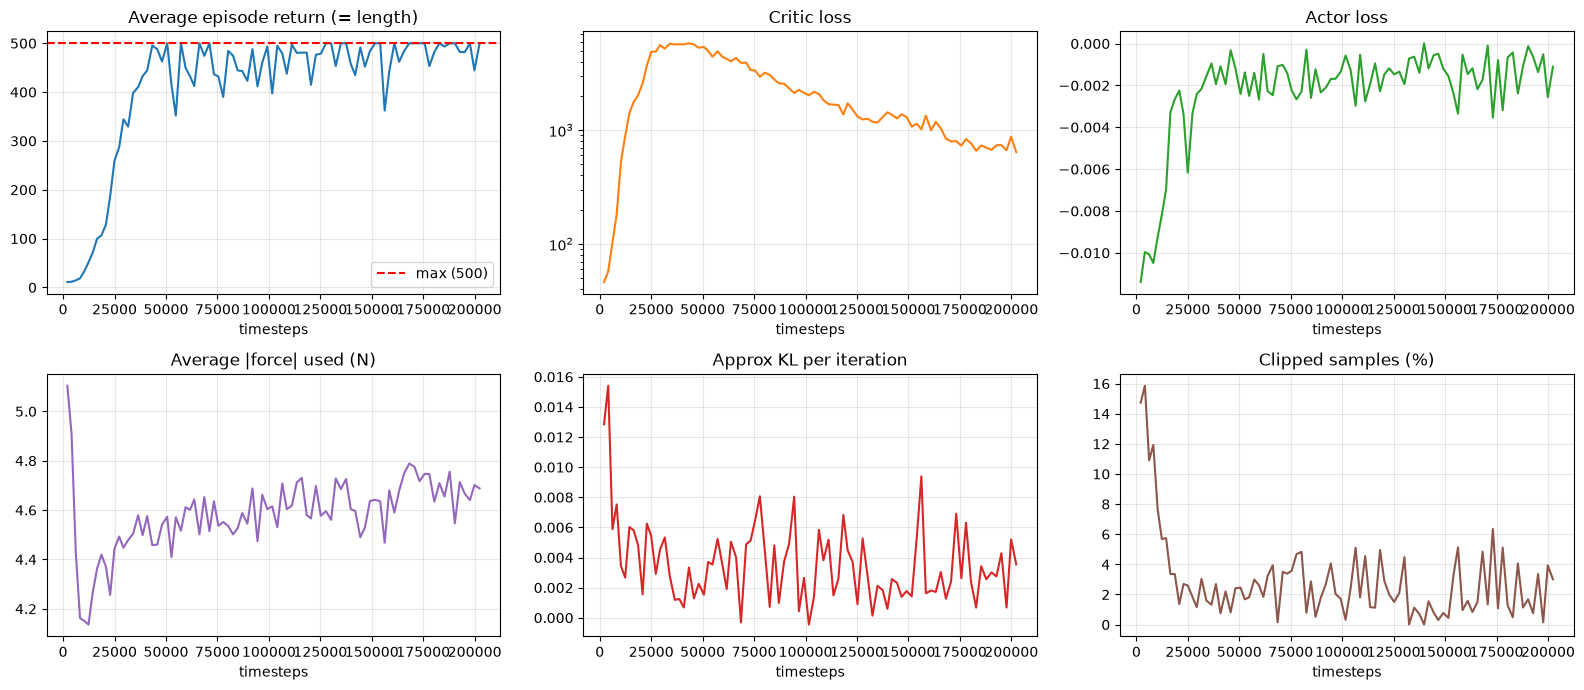

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))

axes[0, 0].plot(hist_timesteps, hist_ep_return)
axes[0, 0].axhline(max_timesteps_per_episode, color='r', ls='--', label='max (500)')
axes[0, 0].set_title("Average episode return (= length)"); axes[0, 0].set_xlabel("timesteps"); axes[0, 0].legend()

axes[0, 1].plot(hist_timesteps, hist_critic_loss, color='tab:orange')
axes[0, 1].set_title("Critic loss"); axes[0, 1].set_xlabel("timesteps"); axes[0, 1].set_yscale('log')

axes[0, 2].plot(hist_timesteps, hist_actor_loss, color='tab:green')
axes[0, 2].set_title("Actor loss"); axes[0, 2].set_xlabel("timesteps")

axes[1, 0].plot(hist_timesteps, hist_force, color='tab:purple')
axes[1, 0].set_title("Average |force| used (N)"); axes[1, 0].set_xlabel("timesteps")

axes[1, 1].plot(hist_timesteps, hist_kl, color='tab:red')
axes[1, 1].set_title("Approx KL per iteration"); axes[1, 1].set_xlabel("timesteps")

axes[1, 2].plot(hist_timesteps, hist_clipped, color='tab:brown')
axes[1, 2].set_title("Clipped samples (%)"); axes[1, 2].set_xlabel("timesteps")

for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Stage 12. Watch the trained actor

For evaluation we use the actor's **mean action directly** (no noise), so the behaviour is deterministic given the start state. We run 3 episodes with the usual random start, record the first one in detail, and draw it with Matplotlib (no pop-up window needed, so it works in Jupyter).

The drawing uses the same geometry as your `draw_cartpole`: the pole tip is at `(x + l sin(theta), l cos(theta))`.

Episode #0 | length 500 | return 500
Episode #1 | length 500 | return 500
Episode #2 | length 500 | return 500

Average evaluation return: 500.0 (max possible 500)


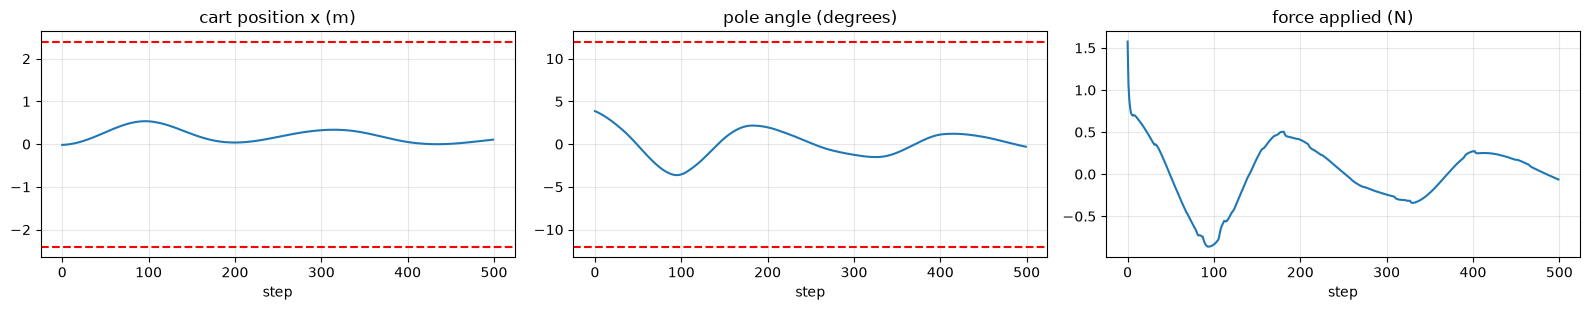

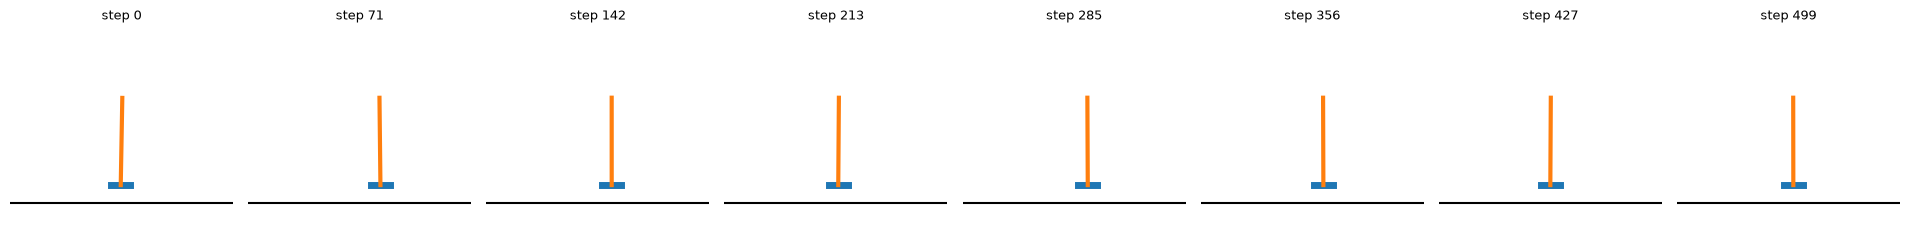

In [23]:
eval_returns = []
traj = {"x": [], "theta": [], "force": [], "state": []}

for ep_num in range(3):
    obs = env.reset()
    done = False
    ep_len, ep_ret = 0, 0
    while not done and ep_len < max_timesteps_per_episode:
        if ep_num == 0:
            traj["state"].append(list(obs)); traj["x"].append(obs[0]); traj["theta"].append(obs[2])
        with torch.no_grad():
            action = actor(torch.tensor(obs, dtype=torch.float)).item()      # mean action, no noise
        force = max(-env.force_mag, min(env.force_mag, action * env.force_mag))
        if ep_num == 0:
            traj["force"].append(force)
        obs = env.step(force)
        done = env.is_done()
        ep_len += 1
        ep_ret += 1.0
    eval_returns.append(ep_ret)
    print(f"Episode #{ep_num} | length {ep_len} | return {ep_ret:.0f}")

print("\nAverage evaluation return: %.1f (max possible %d)" % (np.mean(eval_returns), max_timesteps_per_episode))

# --- trajectory plots of the first evaluation episode ---
fig, ax = plt.subplots(1, 3, figsize=(16, 3.2))
ax[0].plot(traj["x"]); ax[0].axhline(2.4, color='r', ls='--'); ax[0].axhline(-2.4, color='r', ls='--')
ax[0].set_title("cart position x (m)"); ax[0].set_xlabel("step")
ax[1].plot(np.degrees(traj["theta"])); ax[1].axhline(12, color='r', ls='--'); ax[1].axhline(-12, color='r', ls='--')
ax[1].set_title("pole angle (degrees)"); ax[1].set_xlabel("step")
ax[2].plot(traj["force"]); ax[2].set_title("force applied (N)"); ax[2].set_xlabel("step")
for a_ in ax: a_.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# --- snapshots of the cart and pole (same geometry as draw_cartpole) ---
n_show = 8
idxs = np.linspace(0, len(traj["state"]) - 1, n_show).astype(int)
fig, axes = plt.subplots(1, n_show, figsize=(2.4 * n_show, 2.4))
for ax_, k in zip(axes, idxs):
    x_, xd_, th_, thd_ = traj["state"][k]
    pole_x = x_ + env.length * math.sin(th_)
    pole_y = env.length * math.cos(th_)
    ax_.plot([-2.4, 2.4], [0, 0], color='k')
    ax_.plot([x_ - 0.2, x_ + 0.2], [0.1, 0.1], linewidth=5)
    ax_.plot([x_, pole_x], [0.1, 0.1 + pole_y], linewidth=3)
    ax_.set_xlim(-2.4, 2.4); ax_.set_ylim(-0.1, 1.0)
    ax_.set_title(f"step {k}", fontsize=9); ax_.axis('off')
plt.tight_layout(); plt.show()

### Optional: animate it

This builds a small animation inside the notebook (the Jupyter equivalent of your `plt.pause` loop, but it does not block).

In [24]:
from matplotlib import animation
from IPython.display import HTML

states = traj["state"][::2][:150]       # every 2nd step, at most 150 frames
fig, ax_ = plt.subplots(figsize=(6, 3))
ax_.set_xlim(-2.4, 2.4); ax_.set_ylim(-0.1, 1.0)
ax_.plot([-2.4, 2.4], [0, 0], color='k')
cart_line, = ax_.plot([], [], linewidth=5)
pole_line, = ax_.plot([], [], linewidth=3)

def _update(i):
    x_, _, th_, _ = states[i]
    cart_line.set_data([x_ - 0.2, x_ + 0.2], [0.1, 0.1])
    pole_line.set_data([x_, x_ + env.length * math.sin(th_)], [0.1, 0.1 + env.length * math.cos(th_)])
    return cart_line, pole_line

anim = animation.FuncAnimation(fig, _update, frames=len(states), interval=40, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## Stage 13. (Optional) Save and reload

Training saved `ppo_cartpole_actor.pth` and `ppo_cartpole_critic.pth` every 10 iterations. To reuse them in a fresh kernel (after running Stages 0 to 3):

In [ ]:
# actor.load_state_dict(torch.load('./ppo_cartpole_actor.pth'))
# critic.load_state_dict(torch.load('./ppo_cartpole_critic.pth'))
# print("loaded")

# Part C: Debugging, comparison, and when to use PPO

## Debugging checklist

| Symptom | Likely cause | What to check |
|---|---|---|
| Ratio is not 1.000 before the first update | Actor or covariance changed between rollout and update, or `log_prob` was stored without `detach()` / with a different `cov_mat` | Print `ratios.min(), ratios.max()` right after the rollout (Stage 8) |
| Average length stays around 10-20 and never grows | Exploration noise too large (pole falls from the noise alone) or too small (no useful variation) | Try `action_std` in `{0.05, 0.1, 0.2}` and compare the first 20 iterations |
| Learning is unstable: length rises, then collapses | Updates too aggressive | Lower `lr`, lower `n_updates_per_iteration`, watch approx KL and clipped % |
| Clipped % is always near 0 | Updates are tiny; the clip never matters | Fine if learning progresses; otherwise raise `lr` |
| Clipped % is above about 50% | Policy moves far each iteration | Lower `lr` or the number of updates |
| Critic loss stays huge for a long time | Critic too slow for the target scale (rewards-to-go up to about 99). Rising at first is normal; it should flatten and then fall | Check `batch_rtgs` range; try a higher critic learning rate |
| Actor loss never looks like it "improves" | Expected: advantages are normalised | Use the episode length curve as the progress metric |
| Advantage mean is not about 0 after normalisation | Forgot to normalise, or normalised the wrong tensor | Print `A_k.mean(), A_k.std()` (Stage 7) |
| Returns look mixed across episodes | Reward-to-go not reset at the episode start | Check `discounted_reward = 0` inside the outer loop (Stage 6) |
| Same result every run although `seed=None` | Seed set somewhere else | Check Stage 1 and Stage 10 |
| Works in training, fails in evaluation | Evaluation uses the mean action; policy may rely on noise | Run evaluation with sampling too and compare |

## Comparison with the previous algorithms

| | Hill climbing | REINFORCE | Actor-critic / A2C | **PPO** |
|---|---|---|---|---|
| Uses gradients | no | yes | yes | yes |
| Learns from | whole-episode reward | whole-episode returns | per-step advantages | per-step advantages |
| Baseline / critic | none | optional | yes | yes |
| Variance | very high | high | lower | lower |
| Data reuse | none | one step per batch | one step per batch | **about 10 steps per batch, made safe by the clip** |
| Step-size safety | accept/reject | none | none | **clip keeps the policy close to the old one** |
| Extra machinery | none | none | critic loss | critic loss + stored old log-probs + ratio + clip |
| Where it fails | scaling to big networks | noisy, unstable | sensitive to step size | needs tuning; still on-policy so data-hungry compared with off-policy methods |

**Comparing with your hill-climbing experiment on the same CartPole:** hill climbing perturbed 4 numbers (a linear controller) and needed whole episodes to judge every candidate.
PPO trains thousands of weights with a learning signal on *every single step* (the advantage), so it improves much faster per episode and can represent non-linear controllers.

## "When would I use this?" scenarios

1. **Continuous control of a simulated robot where simulation is cheap and parallelisable.** PPO is a strong default: stable and simple.
2. **Fine-tuning a language model with a reward model (RLHF).** PPO is the classic choice, because the clip prevents the model from drifting too far per update. (Later in your course: PPO for LLMs, then GRPO.)
3. **Sparse, hard-to-explore game rewards.** PPO alone struggles; you would add exploration bonuses or curiosity.
4. **Real-world robot where each sample is expensive and a crash is costly.** Prefer an off-policy method (SAC/TD3) or learn a model first, because PPO throws away its data after each iteration.
5. **A tiny problem with 20 states.** Do not use PPO. Tabular Q-learning or dynamic programming is simpler and exact.

# Experiments to try (change one thing at a time)

1. **Exploration noise:** `action_std = 0.05, 0.1, 0.3`. How does the first 20 iterations' average length change?
2. **Clip range:** `clip = 0.05, 0.2, 0.5`. Watch the clipped % and approx KL. What happens with `clip = 1000` (effectively no clipping)?
3. **Number of updates:** `n_updates_per_iteration = 1, 10, 50`. Where does stability break?
4. **Batch size:** `timesteps_per_batch = 512, 2048, 8192`. How does the learning curve noise change?
5. **No advantage normalisation:** comment out the normalisation line in the loop. Does it still learn?
6. **No critic baseline:** use `A_k = batch_rtgs` (this is REINFORCE with rewards-to-go). Compare the learning curves.
7. **Truncation bootstrap:** for episodes that hit 500 steps, add `gamma^k * V(s_last)` to their rewards-to-go. Does training become smoother near the end?
8. **Original deterministic start:** `CartPole(start_noise=0.0)`. Does the policy still generalise to random starts in Stage 12?
9. **Learn the standard deviation** instead of fixing it (add a `log_std` parameter to the actor optimiser).
10. **Harder physics:** `env.mass_pole = 0.5`, or `env.force_mag = 10.0`, and see whether the same PPO still learns.